# NASA Kepler — MLP Architecture Optimization



In [ ]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, roc_auc_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

DATA_DIR = Path("Kepler_Datasets")


def read_csv(name):
    file_path = DATA_DIR / name
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Could not find {file_path.resolve()}"
        )
    return pd.read_csv(file_path)


X = read_csv('X_train.csv')
y = read_csv('y_train.csv')['target'].astype(int).to_numpy()
groups = read_csv('train_ids.csv')['kepid'].to_numpy()


assert len(X) == len(y) == len(groups)
assert X.shape[1] == 19

print('Train rows:', len(X))
print('Features:', X.shape[1])
print('Host stars:', len(np.unique(groups)))


Train rows: 7662
Features: 19
Host stars: 6571


## 1. Candidate architectures

We compare five architectures with a controlled setup. Each uses ReLU, Adam, L2 regularization, batch size 128, learning rate 0.001 and **up to 90 epochs/iterations**. We report number of learned weights and biases as a measure of complexity. All configurations use the same folds and no test labels.

In [2]:
configs = [
    ('MLP 16', (16,), 0.01),
    ('MLP 32 baseline', (32,), 0.01),
    ('MLP 64', (64,), 0.01),
    ('MLP 64-32', (64, 32), 0.01),
    ('MLP 32 stronger L2', (32,), 0.1),
]
cv = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, y, groups))

def make_model(hidden, alpha):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('mlp', MLPClassifier(hidden_layer_sizes=hidden, activation='relu', solver='adam',
                             alpha=alpha, learning_rate_init=0.001, batch_size=128,
                             max_iter=90, n_iter_no_change=20, tol=1e-4,
                             early_stopping=False, random_state=42))
    ])

def metrics(y_true, model, inputs):
    pred = model.predict(inputs)
    prob = model.predict_proba(inputs)[:, 1]
    return dict(F1=f1_score(y_true,pred), Precision=precision_score(y_true,pred,zero_division=0),
                Recall=recall_score(y_true,pred,zero_division=0), Accuracy=accuracy_score(y_true,pred),
                ROC_AUC=roc_auc_score(y_true,prob))

## 2. Train every configuration across the same five folds

This recomputes all results and saves fold-level scores for auditability. Training and validation scores are computed separately.

In [3]:
rows = []
for name, hidden, alpha in configs:
    start = time.perf_counter()
    for fold,(tr,va) in enumerate(cv,1):
        model = make_model(hidden,alpha)
        model.fit(X.iloc[tr],y[tr])
        net = model.named_steps['mlp']
        params = sum(w.size for w in net.coefs_)+sum(b.size for b in net.intercepts_)
        for split,idx in [('Training',tr),('Validation',va)]:
            rows.append(dict(Config=name,Fold=fold,Split=split,N=len(idx),
                             **metrics(y[idx],model,X.iloc[idx]),
                             Parameters=params,Iterations=net.n_iter_))
    print(f'{name}: complete in {time.perf_counter()-start:.1f}s')
fold_scores=pd.DataFrame(rows)
fold_scores.to_csv('mlp_optimization_folds.csv',index=False)
summary=fold_scores.groupby(['Config','Split'])[['F1','Precision','Recall','Accuracy','ROC_AUC','Parameters','Iterations']].mean().reset_index()
summary.to_csv('mlp_optimization_summary.csv',index=False)
validation=summary.query("Split=='Validation'").sort_values('F1',ascending=False)
display(validation.round(4))

MLP 16: complete in 4.4s
MLP 32 baseline: complete in 5.0s
MLP 64: complete in 5.5s
MLP 64-32: complete in 8.7s
MLP 32 stronger L2: complete in 5.0s


,Config,Split,F1,Precision,Recall,Accuracy,ROC_AUC,Parameters,Iterations
9,MLP 64-32,Validation,0.8281,0.8198,0.8383,0.8272,0.9110,3393.0,90.0
7,MLP 64,Validation,0.8273,0.8031,0.8533,0.8230,0.9073,1345.0,90.0
3,MLP 32 baseline,Validation,0.8262,0.7956,0.8594,0.8204,0.9028,673.0,90.0
5,MLP 32 stronger L2,Validation,0.8239,0.7919,0.8588,0.8177,0.9003,673.0,90.0
1,MLP 16,Validation,0.8182,0.7983,0.8394,0.8148,0.8975,337.0,90.0


## 3. Training vs. validation and overfitting

The F1 gap is mean training F1 minus mean validation F1. A larger gap may indicate overfitting, especially as model size increases.

Split,Training,Validation,F1 gap
Config,,,
MLP 64-32,0.8607,0.8281,0.0326
MLP 64,0.8410,0.8273,0.0137
MLP 32 baseline,0.8358,0.8262,0.0096
MLP 32 stronger L2,0.8305,0.8239,0.0066
MLP 16,0.8262,0.8182,0.0080


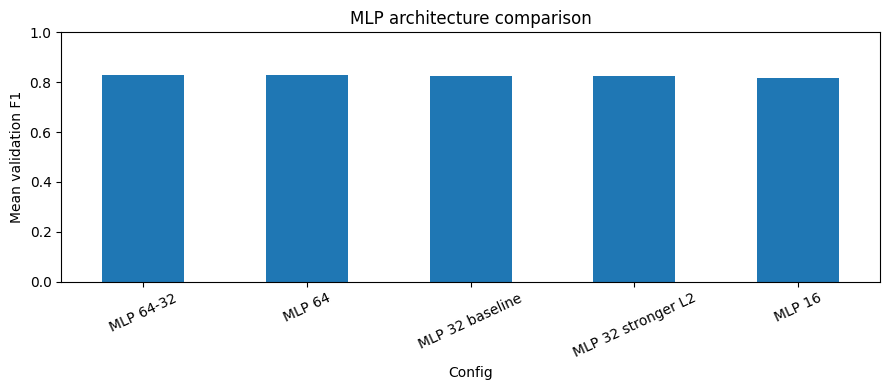

In [4]:
wide=summary.pivot(index='Config',columns='Split',values='F1')
wide['F1 gap']=wide['Training']-wide['Validation']
display(wide.sort_values('Validation',ascending=False).round(4))
ax=validation.plot.bar(x='Config',y='F1',legend=False,figsize=(9,4),rot=25)
ax.set_ylabel('Mean validation F1'); ax.set_ylim(0,1);ax.set_title('MLP architecture comparison');plt.tight_layout();plt.show()

## 4. Decision Tree comparison

Reference: tuned Decision Tree five-fold validation F1 = **0.8154** using the same group-aware folds. Since these candidates were selected by comparing validation F1, their highest validation result may be optimistic. Differences this small need caution.

In [6]:
tree_f1=0.8154
best=validation.iloc[0]
print('Best candidate:',best['Config'])
print(f"Validation F1: {best['F1']:.4f}")
print(f"Difference vs. Decision Tree: {best['F1']-tree_f1:+.4f}")
print(f"Parameter count: {best['Parameters']:.0f}")

Best candidate: MLP 64-32
Validation F1: 0.8281
Difference vs. Decision Tree: +0.0127
Parameter count: 3393


## 5. Fit the selected MLP on all training observations


In [7]:
best_name=best['Config']
_,hidden,alpha=next(c for c in configs if c[0]==best_name)
final_model=make_model(hidden,alpha)
final_model.fit(X,y)
joblib.dump(final_model,'kepler_mlp_optimized.joblib')
print('Saved: kepler_mlp_optimized.joblib')

Saved: kepler_mlp_optimized.joblib
